# First models: DINO ViT-S/16 vs supervised DeiT-S/16



In [1]:
from google.colab import drive
drive.mount("/content/drive")

import glob, os, zipfile

ZIP_PATH = "/content/drive/MyDrive/Visual_retrieval_system.zip"
if not os.path.exists(ZIP_PATH):
    found = glob.glob("/content/drive/MyDrive/**/Visual_retrieval_system*.zip", recursive=True)
    assert found, "Архив не найден на Google Drive: укажи ZIP_PATH вручную"
    ZIP_PATH = found[0]
print("zip:", ZIP_PATH)

if not os.path.exists("/content/Visual_retrieval_system"):
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall("/content")
%cd /content/Visual_retrieval_system

!pip install -q timm scikit-learn pandas tqdm pyyaml
import torch; print(torch.__version__, torch.cuda.is_available(), torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

Mounted at /content/drive
zip: /content/drive/MyDrive/Visual_retrieval_system.zip
/content/Visual_retrieval_system
2.11.0+cu130 True Tesla T4


In [2]:
# 2. Данные + split. Скачивает Oxford-IIIT Pet (~800 MB) и пишет configs/split_manifest.csv
!python scripts/prepare_data.py
# Ожидается: gallery 1840, val 1840, test 3669, 37 пород

100% 792M/792M [00:24<00:00, 32.5MB/s]
100% 19.2M/19.2M [00:01<00:00, 17.9MB/s]
images: 7349  breeds: 37
gallery: 1840  val: 1840  test: 3669
saved /content/Visual_retrieval_system/configs/split_manifest.csv


In [3]:
# 3. Эмбеддинги галереи, метрики на val/test, времена. Результат: results/first_models/
!python scripts/evaluate.py

skipping 'dinov2_vit_b14': not registered yet (adapter not implemented)
skipping 'deit_vit_b16_supervised': not registered yet (adapter not implemented)

=== DINO ViT-S/16 (dino_vit_s16) on cuda ===
Downloading: "https://github.com/facebookresearch/dino/zipball/main" to /root/.cache/torch/hub/main.zip
Downloading: "https://dl.fbaipublicfiles.com/dino/dino_deitsmall16_pretrain/dino_deitsmall16_pretrain.pth" to /root/.cache/torch/hub/checkpoints/dino_deitsmall16_pretrain.pth
100% 82.7M/82.7M [00:00<00:00, 242MB/s]
gallery: (1840, 384), build time 17.6 s
 val: P@5=0.8609  R@5=0.0866  P@10=0.8278  R@10=0.1665  Hit@5=0.9826
test: P@5=0.8416  R@5=0.0847  P@10=0.8156  R@10=0.1641  Hit@5=0.9747
query latency (median): embed 7.65 ms, search 0.346 ms, preprocess 7.7 ms

=== DeiT-S/16 (supervised) (deit_vit_s16_supervised) on cuda ===

model.safetensors: downloading bytes:  95% 83.4M/88.2M [00:03<00:00, 61.2MB/s, 5.57MB/s  ]
model.safetensors: downloading bytes: 100% 83.4M/83.4M [00:03<00:00, 21.

In [4]:
import pandas as pd
from IPython.display import display
display(pd.read_csv("results/first_models/metrics.csv").round(4))
display(pd.read_csv("results/first_models/timing.csv").round(3))

,model,split,P@5,R@5,P@10,R@10,Hit@5
0,DeiT-S/16 (supervised),val,0.8883,0.0893,0.8692,0.1749,0.9859
1,DeiT-S/16 (supervised),test,0.8665,0.0872,0.8527,0.1716,0.9692
2,DINO ViT-S/16,val,0.8609,0.0866,0.8278,0.1665,0.9826
3,DINO ViT-S/16,test,0.8416,0.0847,0.8156,0.1641,0.9747


,model,gallery_build_s,embed_ms_median,search_ms_median,preprocess_ms_median,n_timing_queries,device,batch_size,date
0,DeiT-S/16 (supervised),17.129,8.527,0.450,11.194,200,Tesla T4,64,2026-10-12
1,DINO ViT-S/16,17.630,7.651,0.346,7.706,200,Tesla T4,64,2026-10-12


Using cache found in /root/.cache/torch/hub/facebookresearch_dino_main


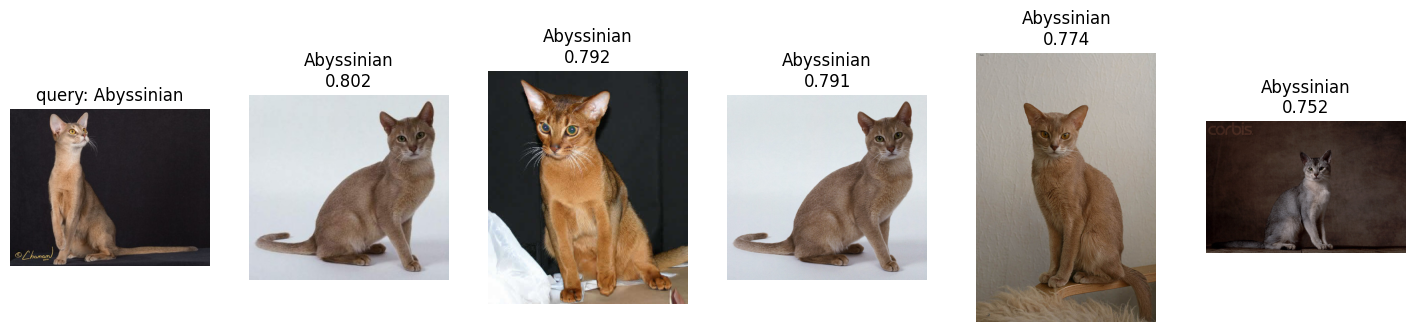

In [5]:
import sys; sys.path.insert(0, "src")
import matplotlib.pyplot as plt
from visual_retrieval import data, models, embeddings, retrieval

name, dev = "dino_vit_s16", ("cuda" if torch.cuda.is_available() else "cpu")
m = data.load_manifest("configs/split_manifest.csv")
gal = data.PetDataset(data.subset(m, "gallery"), "data", embeddings.build_transform())
cached = embeddings.load_embeddings("artifacts", name, "gallery", gal.image_ids)
breeds = dict(zip(m.label, m.breed))
index = retrieval.GalleryIndex(cached.embeddings, gal.image_ids, gal.labels, [breeds[l] for l in gal.labels], device=dev)
encoder = models.load_encoder(name, dev)

q = data.subset(m, "test").iloc[0]
hits = retrieval.query(data.image_path("data", q.image_id), encoder, index, k=5)
fig, ax = plt.subplots(1, 6, figsize=(18, 3.5))
ax[0].imshow(data.load_image(data.image_path("data", q.image_id))); ax[0].set_title(f"query: {q.breed}")
for a, h in zip(ax[1:], hits):
    a.imshow(data.load_image(data.image_path("data", h.image_id))); a.set_title(f"{h.breed}\n{h.score:.3f}")
for a in ax: a.axis("off")
plt.show()

In [6]:
!zip -qr first_models_results.zip configs/split_manifest.csv results/first_models
from google.colab import files; files.download("first_models_results.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>